# Agentic Statistical Analysis Assistant MVP

This notebook executes a real compiled LangGraph and SciPy tools using synthetic data.
**Default mode is an offline deterministic test double, not an LLM.** To validate real agents, configure this project's DeepSeek API key, set `LIVE=True`, and rerun. Offline tests do not establish natural-language accuracy.

Planner: map intent to variable roles and ask about study design. Interpreter: consume the plan and numerical tool results; produce a cautious explanation. Other nodes are deterministic tools. No automatic nonparametric fallback or significance-driven method search.

In [1]:
from pathlib import Path
import json
from IPython.display import Image, display
from langgraph.types import Command
from stat_assistant.agents import OfflineAgents, DeepSeekAgents, load_local_env
from stat_assistant.workflow import build_graph
from demo import fixtures, public_result

LIVE = False
load_local_env(Path('.env'))
agents = DeepSeekAgents() if LIVE else OfflineAgents()
graph = build_graph(agents)
trial, corr = fixtures()
print('Mode:', agents.mode)
display(trial.head())

Mode: offline-test-double


,group,outcome
0,control,0.304717
1,control,-1.039984
2,control,0.750451
3,control,0.940565
4,control,-1.951035


## A concrete comparison
Question: compare mean outcome between treatment and control. CSV does not prove independence. The graph pauses for explicit user metadata; resume happens in a separate node and does not repeat the planner API call.

In [2]:
config = {'configurable': {'thread_id': 'notebook-trial'}}
pending = graph.invoke({'data': trial.to_dict(orient='records'), 'question': 'Compare mean outcome between treatment and control.', 'metadata': {}}, config)
print('Paused:', '__interrupt__' in pending)
if '__interrupt__' in pending:
    display(pending['__interrupt__'][0].value)
    result = graph.invoke(Command(resume={'design': 'independent', 'study_type': 'observational'}), config)
else:
    result = pending
display(public_result(result))

Paused: True


{'question': 'Confirm independent/paired/clustered design, study type and variable roles.',
 'plan': {'goal': 'difference',
  'outcome': 'outcome',
  'group': 'group',
  'x': None,
  'y': None,
  'design': 'unknown',
  'study_type': 'unknown',
  'filter': None,
  'reason': 'Demonstration of independent-group mean comparison.',
  'clarification': None},
 'accepted_keys': ['design',
  'study_type',
  'outcome',
  'group',
  'x',
  'y',
  'filter']}

{'mode': 'offline-test-double',
 'status': 'completed',
 'plan': {'goal': 'difference',
  'outcome': 'outcome',
  'group': 'group',
  'x': None,
  'y': None,
  'design': 'independent',
  'study_type': 'observational',
  'filter': None,
  'reason': 'After user clarification: goal=difference; design=independent; study_type=observational; variable roles: outcome=outcome, group=group, x=None, y=None. Current user confirmations supersede the earlier missing-information assessment; method rules still require checks.',
  'clarification': None},
 'method': 'welch_t_test',
 'diagnostics': {'errors': [],
  'warnings': ['Welch does not require equal variances; independence is user-confirmed, not verified from CSV.',
   'Study design does not establish causality. Report association or group differences only.'],
  'details': {'rows': 50,
   'usable': 50,
   'dropped': 0,
   'groups': {'control': {'n': 25,
     'constant': False,
     'skew': -0.39807980739938575,
     'outliers': 0,
     'extreme':

## Short-term memory and follow-up
Reuse column roles and intent, not old conclusions. This example defines the year explicitly; an ambiguous "last year" must ask for date boundaries. The same thread retains the dataset, but diagnostics and statistics are recomputed.

In [3]:
config_corr = {'configurable': {'thread_id': 'notebook-correlation'}}
first = graph.invoke({'data': corr.to_dict(orient='records'), 'question': 'Pearson correlation between x and y', 'metadata': {'design': 'independent'}}, config_corr)
follow = graph.invoke({'question': 'Only calendar year 2025', 'metadata': {'design': 'independent', 'filter': {'column': 'date', 'start': '2025-01-01', 'end': '2025-12-31'}}}, config_corr)
print('Full n:', first['result']['n'], 'subset n:', follow['result']['n'])
display(public_result(follow))

Full n: 20 subset n: 10


{'mode': 'offline-test-double',
 'status': 'completed',
 'plan': {'goal': 'correlation',
  'outcome': None,
  'group': None,
  'x': 'x',
  'y': 'y',
  'design': 'independent',
  'study_type': 'unknown',
  'filter': {'column': 'date', 'start': '2025-01-01', 'end': '2025-12-31'},
  'reason': 'Demonstration of numeric linear association.',
  'clarification': None},
 'method': 'pearson',
 'diagnostics': {'errors': [],
  'warnings': ['Pearson measures linear association; design, linearity and default inference assumptions are not guaranteed by these diagnostics.',
   'Study design does not establish causality. Report association or group differences only.'],
  'details': {'rows': 10,
   'usable': 10,
   'dropped': 0,
   'variables': {'x': {'n': 10,
     'constant': False,
     'skew': 0.0,
     'outliers': 0,
     'extreme': 0,
     'shapiro_p': 0.8923673075239196},
    'y': {'n': 10,
     'constant': False,
     'skew': -0.3041818019115628,
     'outliers': 0,
     'extreme': 0,
     'shap

## Unsupported design is handled, not hidden
Paired observations are outside the independent-sample MVP. Stopping is correct behavior, not a genuine system failure. A course breaking scenario must be an actual observed incorrect behavior, preferably from real model evaluation. Interpretation heuristics cannot guarantee semantic correctness.

In [4]:
stopped = graph.invoke({'data': trial.to_dict(orient='records'), 'question': 'Compare outcome between groups', 'metadata': {'design': 'paired'}}, {'configurable': {'thread_id': 'notebook-paired'}})
display(public_result(stopped))

{'mode': 'offline-test-double',
 'status': 'stopped',
 'plan': {'goal': 'difference',
  'outcome': 'outcome',
  'group': 'group',
  'x': None,
  'y': None,
  'design': 'paired',
  'study_type': 'unknown',
  'filter': None,
  'reason': 'Demonstration of independent-group mean comparison.',
  'clarification': None},
 'method': 'welch_t_test',
 'diagnostics': {'errors': ['Independent observations must be confirmed; paired/clustered designs are not supported.'],
  'warnings': ['Welch does not require equal variances; independence is user-confirmed, not verified from CSV.',
   'Study design does not establish causality. Report association or group differences only.'],
  'details': {'rows': 50,
   'usable': 50,
   'dropped': 0,
   'groups': {'control': {'n': 25,
     'constant': False,
     'skew': -0.39807980739938575,
     'outliers': 0,
     'extreme': 0,
     'shapiro_p': 0.5649965949945506},
    'treatment': {'n': 25,
     'constant': False,
     'skew': 0.49790310962820655,
     'outli

## Diagram of this actual compiled graph
Each edge is an execution transition. Conditional edges depend on missing metadata, diagnostics, retry count or text checks. Handoff: Planner plan -> method/tools; plan + tool results -> Interpreter; draft -> critique. Ask-user uses an interrupt and resume.

PNG rendering uses LangGraph's built-in Mermaid renderer; network access to the renderer is required. The Mermaid source is always exported directly from this graph.

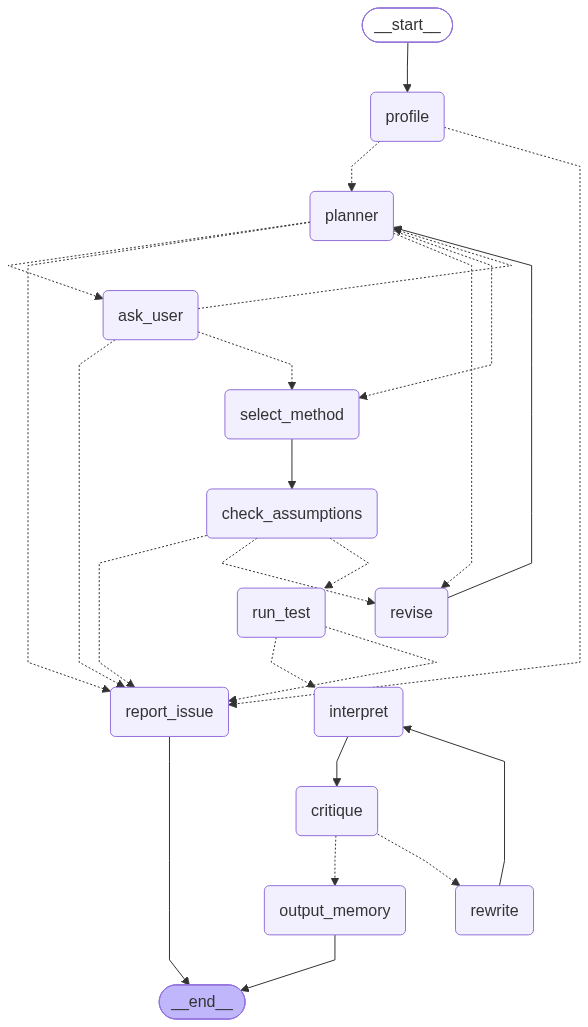

In [5]:
Path('artifacts').mkdir(exist_ok=True)
Path('artifacts/graph.mmd').write_text(graph.get_graph().draw_mermaid(), encoding='utf-8')
try:
    png = graph.get_graph().draw_mermaid_png()
    Path('artifacts/graph.png').write_bytes(png)
    display(Image(png))
except Exception as exc:
    print('PNG rendering unavailable:', type(exc).__name__, '- use graph.mmd or rerun with network access.')